This notebook plots Fig 9 from the main text, and Fig. S5 from the SM, which compare directly SPDC-M and M-M

In [9]:
using CairoMakie
using LaTeXStrings
include("Protocol_Fns.jl")

gen_probs (generic function with 1 method)

In [10]:
##### parameters set I - optimistic values

F_targ= 0.9 #target fidelity
η_m, η_FC, η_i_io = fill(0.8,3)
η_d, _ = fill(0.9,2)
η_herald = 0.97
effs_SPDC = (η_m, η_d, η_i_io, η_FC, η_herald);
N_bin=10 
M=1000 #multiplexing modes
r=0.4 #dephasing parameter
epsilon_m=0.5; nu = 1; Lambda_0= nu/2; filt_params = (Lambda_0, nu, epsilon_m); #low pass filter parameters

In [11]:
L_array = [100e3, 200e3, 300e3]   # example values

η_array = range(0.1, 1, length=100) #eta_AFC
tau_array = range(5e-6, 500e-6, length=100) #T_EN

M_M_results = Dict()
SPDC_M_results = Dict()

for L in L_array

    # Memory matching
    M_M_results[L] = Dict()
    for (sc_label, sc_key) in [(:SC, true), (:DC, false)]
        for (repeater_label, repeater_key) in [(:repeater, 1), (:no_repeater, 0)]
            for (turn_label, turn_key) in [(:on, false), (:off, true)]
                M_M_results[L][(sc_label, turn_label, repeater_label)] =
                    map(η_AFC -> Memory_Match(
                        repeater_key, L,
                        (η_m, η_d, η_i_io, η_FC, η_AFC, η_herald),
                        F_targ, M, filt_params;
                        single_click = sc_key,
                        r = r,
                        turn_off = turn_key
                    ), η_array)
            end
        end
    end

    # SPDC matching
    # We tie the SPDC (memory) turn-off to the ion turn-off. For SC it has no effect at the order considered; for DC it enters only through I_0 and κ_0 (a small effect).
    SPDC_M_results[L] = Dict()
    for (sc_label, sc_key) in [(:SC, true), (:DC, false)]
        for (repeater_label, repeater_key) in [(:repeater, 1), (:no_repeater, 0)]
            for (turn_label, turn_key) in [(:on, false), (:off, true)]
                SPDC_M_results[L][(sc_label, turn_label, repeater_label)] =
                    map(tau_en_eff -> SPDC_Match(
                        repeater_key, L,
                        effs_SPDC, F_targ, M, N_bin, tau_en_eff;
                        single_click = sc_key,
                        r = r,
                        turn_off = turn_key,
                        turn_off_mem = turn_key
                    ), tau_array)
            end
        end
    end

end

Ratio_time = Dict()
Ratio_time_noR = Dict()

for L in L_array
    T_ent_M_M = first.(M_M_results[L][(:SC, :off, :repeater)])
    T_ent_SPDC_M = first.(SPDC_M_results[L][(:SC, :off, :repeater)])
    Ratio_time[L] = [a/b for a in T_ent_M_M, b in T_ent_SPDC_M]

    T_ent_M_M_noR = first.(M_M_results[L][(:SC, :off, :no_repeater)])
    T_ent_SPDC_M_noR = first.(SPDC_M_results[L][(:SC, :off, :no_repeater)])
    Ratio_time_noR[L] = [a/b for a in T_ent_M_M_noR, b in T_ent_SPDC_M_noR]
end

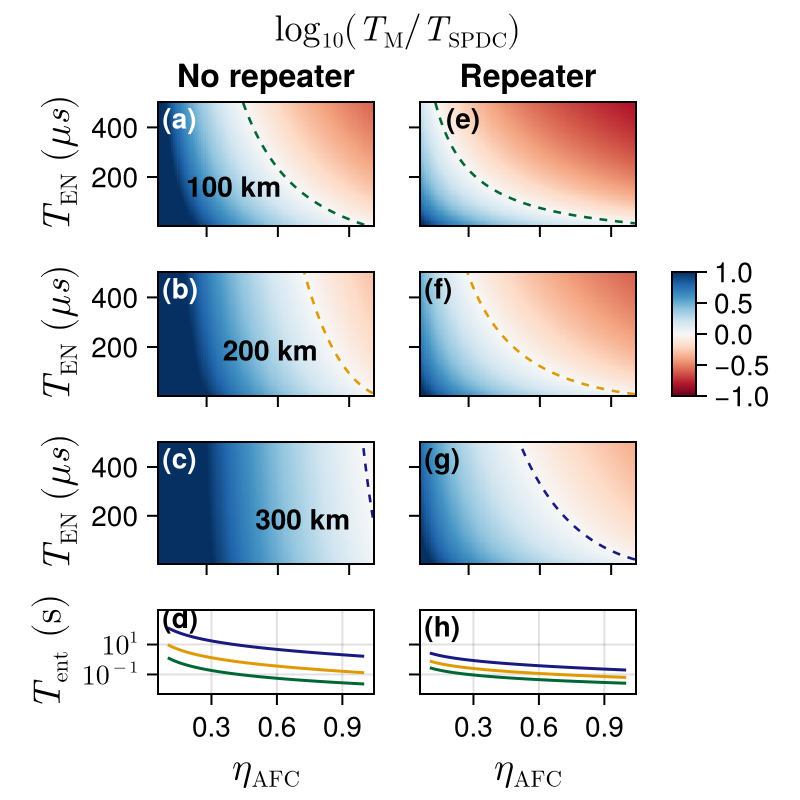

CairoMakie.Screen{IMAGE}


In [12]:
fig9 = Figure(size = (400, 400))

f_size, t_size, y_size = 14, 16, 19
panel_labels = ["(a)", "(e)", "(b)", "(f)", "(c)", "(g)", "(d)"]
# (x, y) position of each label, in the same order as panel_labels
label_pos = [
    (0.02, 1.0),   # (a)
    (0.12, 1.0),   # (e)
    (0.02, 1.0),   # (b)
    (0.02, 1.0),   # (f)
    (0.02, 1.0),   # (c)
    (0.02, 1.0),   # (g)
    (0.02, 1.1),   # (d)
    (0.02, 0.4),   # (h)
]

label_align = fill((:left, :top), length(panel_labels))
yts = [200, 400]
xts = [0.3, 0.6, 0.9]
clim = 1
Cblack = RGBf(0,0,0)
Cwhite = RGBf(1,1,1)
Cols =[RGBf(0.,0.4,0.2), RGBf(0.88,.6, 0.0), RGBf(0.1,0.1, 0.5)]

Label(
    fig9[1, 1:2, Top()],
    L"\log_{10}(T_{\mathrm{M}}/T_{\mathrm{SPDC}})",
    fontsize = 18,
    font = :bold,
    padding = (0, 0, 25, 0),   # adjust last number to move it up/down
)

heat_axes = Matrix{Axis}(undef, 3, 2)

for (i, L) in enumerate(L_array)
    Ratio_time_t = Ratio_time[L]
    Ratio_time_noR_t = Ratio_time_noR[L]
    titleR = i == 1 ? "Repeater" : "";  titlenoR = i == 1 ? "No repeater" : ""
    # Left (no repeater)
    heat_axes[i, 1] = Axis(fig9[i, 1], xlabel = "", ylabel = L"T_{\mathrm{EN}}\;(\mu s)", title = titlenoR, xticklabelsvisible = false, xticks = xts,
        yticks = yts, xlabelsize = y_size, ylabelsize = y_size, titlesize = t_size, xticklabelsize = f_size, yticklabelsize = f_size)
    heatmap!(heat_axes[i, 1], η_array, tau_array .* 1e6, log10.(Ratio_time_noR_t), colormap = :RdBu, colorrange = (-clim, clim))
    # Right (repeater)
    heat_axes[i, 2] = Axis(fig9[i, 2], xlabel = "", ylabel = "", title = titleR, xticklabelsvisible = false, yticklabelsvisible = false, xticks = xts,
        yticks = yts, xlabelsize = y_size, ylabelsize = y_size, titlesize = t_size, xticklabelsize = f_size, yticklabelsize = f_size)
    hm = heatmap!(heat_axes[i, 2], η_array, tau_array .* 1e6, log10.(Ratio_time_t), colormap = :RdBu, colorrange = (-clim, clim))
    if i == 2 Colorbar(fig9[i, 3], hm, label="", labelsize=y_size) end
    contour!(heat_axes[i,1], η_array, tau_array .* 1e6, log10.(Ratio_time_noR_t), levels = [0], color = Cols[i], linewidth = 1.3, linestyle=:dash)
    contour!(heat_axes[i,2], η_array, tau_array .* 1e6, log10.(Ratio_time_t), levels = [0], color = Cols[i], linewidth = 1.3, linestyle=:dash)
end

# Bottom row
ylms = (5e-3, 2e3)

ax21 = Axis(fig9[4, 1], xlabel = L"\eta_{\mathrm{AFC}}", ylabel = L"T_{\mathrm{ent}}\ \mathrm{(s)}", yscale = log10, xticks = xts,
    yticks = ([1e-3, 1e-1, 1e1], [L"10^{-3}", L"10^{-1}", L"10^1"]), xlabelsize = y_size, ylabelsize = y_size, titlesize = t_size, xticklabelsize = f_size, yticklabelsize = f_size)

ax22 = Axis(fig9[4, 2], xlabel = L"\eta_{\mathrm{AFC}}", ylabel = "", yscale = log10, yticklabelsvisible = false, xticks = xts,
    yticks = [1e-3, 1e-1, 1e1], xlabelsize = y_size, ylabelsize = y_size, titlesize = t_size, xticklabelsize = f_size, yticklabelsize = f_size)

for (i, L) in enumerate(L_array)
    lines!(ax21, η_array, first.(M_M_results[L][(:SC, :off, :no_repeater)]), color = Cols[i])
    lines!(ax22, η_array, first.(M_M_results[L][(:SC, :off, :repeater)]),    color = Cols[i])
end

ylims!(ax21, ylms)
ylims!(ax22, ylms)

axes = [heat_axes[1,1], heat_axes[1,2], heat_axes[2,1], heat_axes[2,2],
        heat_axes[3,1], heat_axes[3,2], ax21, ax22]
white_label_axes = (heat_axes[1,1], heat_axes[2,1], heat_axes[3,1])

for (ax, label, pos, al) in zip(axes, panel_labels, label_pos, label_align)
    text!(ax, pos...; text = label, space = :relative, align = al,
          fontsize = 14, font = :bold,
          color = any(a -> a === ax, white_label_axes) ? Cwhite : Cblack)
end

text!(ax22, 0.02, 1; text = "(h)", space = :relative, align = (:left, :top), fontsize = 14, font = :bold, color =  Cblack)
text!(heat_axes[1,1], 0.13, 0.45, text = "100 km", space = :relative, align = (:left, :top), fontsize = 14, font = :bold, color =  Cblack)
text!(heat_axes[2,1], 0.3, 0.5, text = "200 km", space = :relative, align = (:left, :top), fontsize = 14, font = :bold, color =  Cblack)
text!(heat_axes[3,1], 0.45, 0.5, text = "300 km", space = :relative, align = (:left, :top), fontsize = 14, font = :bold, color =  Cblack)
for i in 1:3
    rowsize!(fig9.layout, i, Relative(0.3))
end
rowsize!(fig9.layout, 4, Relative(0.2))

#save("Figure_9.pdf", fig9)
display(fig9)


In [13]:
#Now PSetII
#NOTE: we reuse the same data names for simplicity, so the following cells will overwrite the data in the ones above for PSet I

In [14]:
##### parameters set II - more realistic values
F_targ= 0.9 #target fidelity
η_m, η_FC, η_i_io = fill(0.4,3)
η_d = 0.75
η_herald = 0.92
effs_SPDC = (η_m, η_d, η_i_io, η_FC, η_herald);
N_bin=10 
M=500 #multiplexing modes
r=0.4 #dephasing parameter
epsilon_m=0.5; nu = 1; Lambda_0= nu/2; filt_params = (Lambda_0, nu, epsilon_m); #low pass filter parameters


In [15]:
L_array = [100e3, 200e3, 300e3]   # example values

η_array = range(0.1, 1, length=100) #eta_AFC
tau_array = range(5e-6, 500e-6, length=100) #T_EN

M_M_results = Dict()
SPDC_M_results = Dict()

for L in L_array

    # Memory matching
    M_M_results[L] = Dict()
    for (sc_label, sc_key) in [(:SC, true), (:DC, false)]
        for (repeater_label, repeater_key) in [(:repeater, 1), (:no_repeater, 0)]
            for (turn_label, turn_key) in [(:on, false), (:off, true)]
                M_M_results[L][(sc_label, turn_label, repeater_label)] =
                    map(η_AFC -> Memory_Match(
                        repeater_key, L,
                        (η_m, η_d, η_i_io, η_FC, η_AFC, η_herald),
                        F_targ, M, filt_params;
                        single_click = sc_key,
                        r = r,
                        turn_off = turn_key
                    ), η_array)
            end
        end
    end

    # SPDC matching
    # We tie the SPDC (memory) turn-off to the ion turn-off. For SC it has no effect at the order considered; for DC it enters only through I_0 and κ_0 (a small effect).
    SPDC_M_results[L] = Dict()
    for (sc_label, sc_key) in [(:SC, true), (:DC, false)]
        for (repeater_label, repeater_key) in [(:repeater, 1), (:no_repeater, 0)]
            for (turn_label, turn_key) in [(:on, false), (:off, true)]
                SPDC_M_results[L][(sc_label, turn_label, repeater_label)] =
                    map(tau_en_eff -> SPDC_Match(
                        repeater_key, L,
                        effs_SPDC, F_targ, M, N_bin, tau_en_eff;
                        single_click = sc_key,
                        r = r,
                        turn_off = turn_key,
                        turn_off_mem = turn_key
                    ), tau_array)
            end
        end
    end

end

Ratio_time = Dict()
Ratio_time_noR = Dict()

for L in L_array
    T_ent_M_M = first.(M_M_results[L][(:SC, :off, :repeater)])
    T_ent_SPDC_M = first.(SPDC_M_results[L][(:SC, :off, :repeater)])
    Ratio_time[L] = [a/b for a in T_ent_M_M, b in T_ent_SPDC_M]

    T_ent_M_M_noR = first.(M_M_results[L][(:SC, :off, :no_repeater)])
    T_ent_SPDC_M_noR = first.(SPDC_M_results[L][(:SC, :off, :no_repeater)])
    Ratio_time_noR[L] = [a/b for a in T_ent_M_M_noR, b in T_ent_SPDC_M_noR]
end

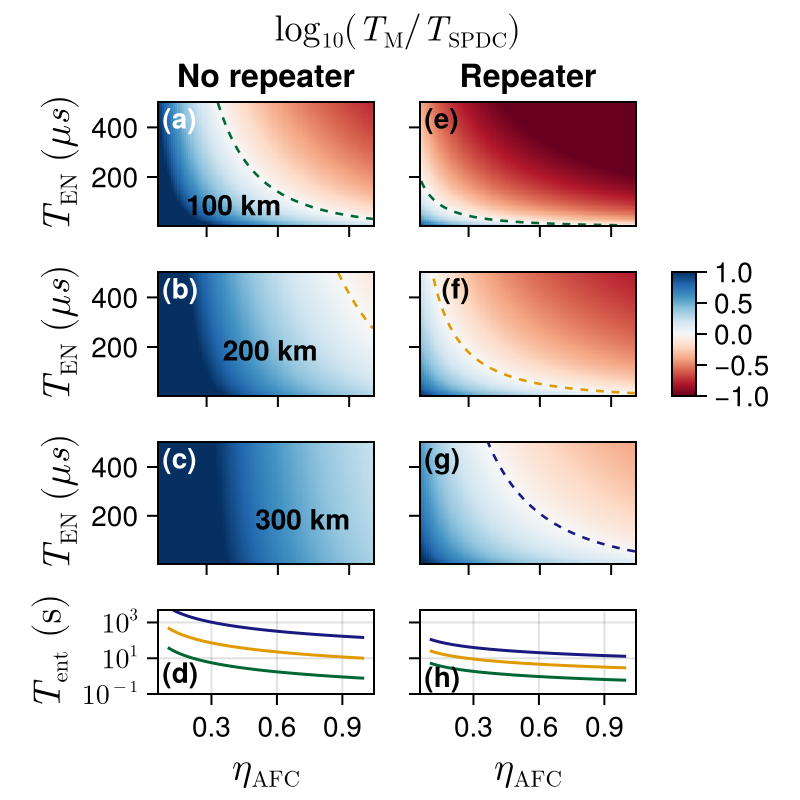

CairoMakie.Screen{IMAGE}


In [16]:
figs5 = Figure(size = (400, 400))

f_size, t_size, y_size = 14, 16, 19
panel_labels = ["(a)", "(e)", "(b)", "(f)", "(c)", "(g)", "(d)"]
# (x, y) position of each label, in the same order as panel_labels
label_pos = [
    (0.02, 1.0),   # (a)
    (0.02, 1.0),   # (e)
    (0.02, 1.0),   # (b)
    (0.1, 1.0),   # (f)
    (0.02, 1.0),   # (c)
    (0.02, 1.0),   # (g)
    (0.02, 0.45),   # (d)
    (0.02, 0.4),   # (h)
]

label_align = fill((:left, :top), length(panel_labels))
yts = [200, 400]
xts = [0.3, 0.6, 0.9]
clim = 1
Cblack = RGBf(0,0,0)
Cwhite = RGBf(1,1,1)
Cols =[RGBf(0.,0.4,0.2), RGBf(0.88,.6, 0.0), RGBf(0.1,0.1, 0.5)]

Label(
    figs5[1, 1:2, Top()],
    L"\log_{10}(T_{\mathrm{M}}/T_{\mathrm{SPDC}})",
    fontsize = 18,
    font = :bold,
    padding = (0, 0, 25, 0),   # adjust last number to move it up/down
)

heat_axes = Matrix{Axis}(undef, 3, 2)

for (i, L) in enumerate(L_array)
    Ratio_time_t = Ratio_time[L]
    Ratio_time_noR_t = Ratio_time_noR[L]
    titleR = i == 1 ? "Repeater" : "";  titlenoR = i == 1 ? "No repeater" : ""
    # Left (no repeater)
    heat_axes[i, 1] = Axis(figs5[i, 1], xlabel = "", ylabel = L"T_{\mathrm{EN}}\;(\mu s)", title = titlenoR, xticklabelsvisible = false, xticks = xts,
        yticks = yts, xlabelsize = y_size, ylabelsize = y_size, titlesize = t_size, xticklabelsize = f_size, yticklabelsize = f_size)
    heatmap!(heat_axes[i, 1], η_array, tau_array .* 1e6, log10.(Ratio_time_noR_t), colormap = :RdBu, colorrange = (-clim, clim))
    # Right (repeater)
    heat_axes[i, 2] = Axis(figs5[i, 2], xlabel = "", ylabel = "", title = titleR, xticklabelsvisible = false, yticklabelsvisible = false, xticks = xts,
        yticks = yts, xlabelsize = y_size, ylabelsize = y_size, titlesize = t_size, xticklabelsize = f_size, yticklabelsize = f_size)
    hm = heatmap!(heat_axes[i, 2], η_array, tau_array .* 1e6, log10.(Ratio_time_t), colormap = :RdBu, colorrange = (-clim, clim))
    if i == 2 Colorbar(figs5[i, 3], hm, label="", labelsize=y_size) end
    contour!(heat_axes[i,1], η_array, tau_array .* 1e6, log10.(Ratio_time_noR_t), levels = [0], color = Cols[i], linewidth = 1.3, linestyle=:dash)
    contour!(heat_axes[i,2], η_array, tau_array .* 1e6, log10.(Ratio_time_t), levels = [0], color = Cols[i], linewidth = 1.3, linestyle=:dash)
end

# Bottom row
ylms = (1e-1, 5e3)

ax21 = Axis(figs5[4, 1], xlabel = L"\eta_{\mathrm{AFC}}", ylabel = L"T_{\mathrm{ent}}\ \mathrm{(s)}", yscale = log10, xticks = xts,
    yticks = ([1e-1, 1e1, 1e3], [L"10^{-1}", L"10^{1}", L"10^{3}"]), xlabelsize = y_size, ylabelsize = y_size, titlesize = t_size, xticklabelsize = f_size, yticklabelsize = f_size)

ax22 = Axis(figs5[4, 2], xlabel = L"\eta_{\mathrm{AFC}}", ylabel = "", yscale = log10, yticklabelsvisible = false, xticks = xts,
    yticks = [1e-1, 1e1, 1e3], xlabelsize = y_size, ylabelsize = y_size, titlesize = t_size, xticklabelsize = f_size, yticklabelsize = f_size)

for (i, L) in enumerate(L_array)
    lines!(ax21, η_array, first.(M_M_results[L][(:SC, :off, :no_repeater)]), color = Cols[i])
    lines!(ax22, η_array, first.(M_M_results[L][(:SC, :off, :repeater)]),    color = Cols[i])
end

ylims!(ax21, ylms)
ylims!(ax22, ylms)

axes = [heat_axes[1,1], heat_axes[1,2], heat_axes[2,1], heat_axes[2,2],
        heat_axes[3,1], heat_axes[3,2], ax21, ax22]
white_label_axes = (heat_axes[1,1], heat_axes[2,1], heat_axes[3,1])

for (ax, label, pos, al) in zip(axes, panel_labels, label_pos, label_align)
    text!(ax, pos...; text = label, space = :relative, align = al,
          fontsize = 14, font = :bold,
          color = any(a -> a === ax, white_label_axes) ? Cwhite : Cblack)
end

text!(ax22, 0.02, 0.4; text = "(h)", space = :relative, align = (:left, :top), fontsize = 14, font = :bold, color =  Cblack)
text!(heat_axes[1,1], 0.13, 0.3, text = "100 km", space = :relative, align = (:left, :top), fontsize = 14, font = :bold, color =  Cblack)
text!(heat_axes[2,1], 0.3, 0.5, text = "200 km", space = :relative, align = (:left, :top), fontsize = 14, font = :bold, color =  Cblack)
text!(heat_axes[3,1], 0.45, 0.5, text = "300 km", space = :relative, align = (:left, :top), fontsize = 14, font = :bold, color =  Cblack)
for i in 1:3
    rowsize!(figs5.layout, i, Relative(0.3))
end
rowsize!(figs5.layout, 4, Relative(0.2))

#save("Fig_S5.pdf", figs5)
display(figs5)